# FL-BENCH-004.4 — FedNova

*Epic EPIC-001 · story fl_bench_004 · all results below are loaded from files produced by the task's experiment function and labelled MEASURED/SIMULATED; clients are virtual; data is synthetic.*

## 1. Research objective
Implement FedNova and verify objective-inconsistency correction on a closed-form quadratic toy.

## 2. Scientific background
Heterogeneous local steps bias FedAvg's fixed point [wang2020fednova].

References use keys of `docs/references/references_master.md` (status per entry).

## 3. Research questions
- **RQ1.** Does the implementation satisfy its validation identities?
- **RQ2.** How does it behave under IID vs non-IID data?

## 4. Hypotheses
- **H1.** Validation identities hold to numerical precision.

## 5. Mathematical formulation
w ← w + τ_eff Σ p_k Δ_k/τ_k; equal τ ⇒ FedAvg.

## 6. Experimental environment

In [1]:
import os, sys, json, platform, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")
def _find_root():
    p = Path(os.environ.get("FL_ROOT") or os.environ.get("RS_ROOT") or Path.cwd()).resolve()
    for q in [p, *p.parents]:
        if (q / "src" / "federated_learning").exists():
            return q
    raise RuntimeError("repository root not found; set RS_ROOT")
ROOT = _find_root()
sys.path.insert(0, str(ROOT / "src"))
STORY = "fl_bench_004"
_cands = [ROOT / "experiments" / "results" / STORY]
RES = next(c for c in _cands if c.exists())
import numpy as np, pandas as pd
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
SEED = 0; np.random.seed(SEED)
def show_csv(name, n=12):
    p = RES / name
    if p.exists(): display(pd.read_csv(p).round(4).head(n))
    else: print("MISSING", name)
def show_fig(name):
    for base in (RES / "figures", RES):
        if (base / name).exists(): display(Image(filename=str(base / name))); return
    print("MISSING figure", name)
print("root:", ROOT, "| results:", RES)

root: /home/claude/fl_sprint | results: /home/claude/fl_sprint/experiments/results/fl_bench_004


In [2]:
import importlib.metadata as md
vers = {}
for p in ["numpy","scipy","scikit-learn","torch","tenseal","phe","pandas","matplotlib","cryptography","psutil","mlflow","opacus"]:
    try: vers[p] = md.version(p)
    except Exception: vers[p] = "not installed"
print(json.dumps(dict(python=platform.python_version(), platform=platform.platform(), versions=vers, seed=SEED, gpu="none (CPU only; GPU metrics NOT_MEASURED)"), indent=1))

{
 "python": "3.13.18",
 "platform": "Linux-6.18.44-fc-v338-x86_64-with-glibc2.39",
 "versions": {
  "numpy": "2.5.3",
  "scipy": "1.18.1",
  "scikit-learn": "1.9.1",
  "torch": "2.15.0",
  "tenseal": "0.3.18",
  "phe": "1.5.0",
  "pandas": "3.0.5",
  "matplotlib": "3.11.2",
  "cryptography": "50.0.1",
  "psutil": "7.2.2",
  "mlflow": "3.18.0",
  "opacus": "1.6.0"
 },
 "seed": 0,
 "gpu": "none (CPU only; GPU metrics NOT_MEASURED)"
}


## 7. Dataset description
Synthetic binary tabular dataset **SYN-IDS-v1** (scikit-learn `make_classification`, 40 features, 70:30 split). Chosen because no real IDS/clinical dataset was available in the sandbox. It has no clinical meaning; conclusions about absolute accuracy do not transfer.

In [3]:
from federated_learning.synthetic_data.generators.syn_ids_v1 import make_dataset, DATASET_ID
from federated_learning.data_partitioning.iid import partition_iid
from federated_learning.data_partitioning.dirichlet import partition_dirichlet
from federated_learning.data_partitioning.metrics import label_skew_stat
data = make_dataset(n_samples=6000, seed=SEED)
print(DATASET_ID, "train", data.X_train.shape, "test", data.X_test.shape, "positive rate", float(data.y_train.mean()))
print("NOTE: SYNTHETIC tabular data (not CIC-IDS-2017, not patient data); clients are VIRTUAL, not hospitals.")

SYN-IDS-v1 train (4200, 40) test (1800, 40) positive rate 0.40095238095238095
NOTE: SYNTHETIC tabular data (not CIC-IDS-2017, not patient data); clients are VIRTUAL, not hospitals.


## 8. Configuration and reproducibility settings
Seeds are fixed; each stored result carries `provenance` (experiment id, SHA-256 of the configuration, environment versions; `git_commit` is `null` because the workspace is not a git repository).

In [4]:
from federated_learning.training.config import FLConfig
cfg = FLConfig(rounds=5, local_epochs=1, seed=SEED)
print(cfg)

FLConfig(algo='fedavg', rounds=5, local_epochs=1, lr=0.05, batch_size=32, participation=1.0, mu=0.0, hidden=32, act='relu', seed=0, hetero_epochs=False, eval_every=1, server_lr=1.0)


## 9. Data preparation
Partitioning into virtual clients (IID or Dirichlet label skew) is performed by `federated_learning.data_partitioning`.

In [5]:
parts_iid = partition_iid(data.y_train, 10, SEED)
parts_dir = partition_dirichlet(data.y_train, 10, 0.3, SEED)
print('label-skew statistic IID:', round(label_skew_stat(data.y_train, parts_iid),3), ' Dirichlet(0.3):', round(label_skew_stat(data.y_train, parts_dir),3))

label-skew statistic IID: 0.019  Dirichlet(0.3): 0.363


## 10. Implementation
Reusable code lives in `src/federated_learning/` (`fl.py`, `stats.py`). The cell below exercises it live (small, fast, deterministic) and asserts correctness.

In [6]:
from federated_learning.training.config import FLConfig
from federated_learning.servers.orchestrator import run_fl
parts = partition_dirichlet(data.y_train, 8, 0.3, SEED)
r = run_fl(FLConfig(algo="fednova", rounds=6, local_epochs=2, mu=0.05, seed=SEED), data, parts)
print("fednova final", {k: round(v, 4) for k, v in r.final.items() if isinstance(v, float)}, "comm MB", round(r.totals["comm_mb"], 3))
assert np.isfinite(r.w).all()

fednova final {'round_time_s': 0.0851, 'agg_time_s': 0.0002, 'client_time_s': 0.0848, 'client_time_max_s': 0.0383, 'acc': 0.785, 'loss': 0.4588, 'precision': 0.6898, 'recall': 0.8419, 'f1': 0.7583, 'specificity': 0.747, 'auc': 0.8818, 'diverged': 0.0} comm MB 0.505


## 11. Experiment execution
The full experiment was executed by `python -m federated_learning.pipelines.experiments.run_all --task FL-BENCH-004.4` (see `logs/`). Its raw per-run results are loaded here; they are not re-computed inside the notebook.

In [7]:
show_csv('task_4_4_runs.csv')
show_csv('task_4_4_quadratic_toy.csv')

,algo,condition,clients,seed,local_epochs,participation,mu,rounds,acc,precision,recall,f1,auc,loss,specificity,rounds_to_target,comm_mb,comm_mb_per_round,train_wall_s,cpu_time_s,rss_peak_mb,skew,pr_auc,ece,hetero_epochs
0,fedavg,dir0.3,10,0,5,1.0,0.0,30,0.8892,0.9032,0.8115,0.8549,0.9552,0.3098,0.9414,7,3.154,0.1051,17.2105,17.09,731.6289,0.3296,0.9376,0.0462,False
1,fedavg,dir0.3,10,1,5,1.0,0.0,30,0.9006,0.9061,0.8398,0.8717,0.9589,0.3175,0.9414,4,3.154,0.1051,18.1258,18.02,731.6289,0.4088,0.9421,0.0497,False
2,fedavg,dir0.3,10,2,5,1.0,0.0,30,0.8686,0.9333,0.7251,0.8162,0.9511,0.3227,0.9651,19,3.154,0.1051,19.0631,18.89,731.6289,0.4206,0.9327,0.0812,False
3,fedavg,dir0.3,10,3,5,1.0,0.0,30,0.8783,0.9384,0.7465,0.8315,0.9537,0.3049,0.9670,16,3.154,0.1051,18.4218,18.29,731.6289,0.3944,0.9368,0.0679,False
4,fedavg,dir0.3,10,4,5,1.0,0.0,30,0.9036,0.9093,0.8446,0.8758,0.9631,0.2759,0.9433,6,3.154,0.1051,17.7947,17.65,731.6289,0.3500,0.9456,0.0372,False
5,fednova,dir0.3,10,0,5,1.0,0.0,30,0.8956,0.9220,0.8087,0.8617,0.9604,0.2901,0.9540,7,3.154,0.1051,18.1419,18.07,731.6289,0.3296,0.9449,0.0474,False
6,fednova,dir0.3,10,1,5,1.0,0.0,30,0.9044,0.9029,0.8543,0.8779,0.9620,0.2929,0.9382,4,3.154,0.1051,19.4347,19.25,731.6289,0.4088,0.9459,0.0426,False
7,fednova,dir0.3,10,2,5,1.0,0.0,30,0.8844,0.9307,0.7700,0.8428,0.9593,0.2874,0.9614,13,3.154,0.1051,18.7880,18.52,731.6289,0.4206,0.9437,0.0652,False
8,fednova,dir0.3,10,3,5,1.0,0.0,30,0.8861,0.9023,0.8039,0.8503,0.9522,0.3161,0.9414,6,3.154,0.1051,17.5774,17.46,731.6289,0.3944,0.9357,0.0495,False
9,fednova,dir0.3,10,4,5,1.0,0.0,30,0.9042,0.8780,0.8847,0.8813,0.9643,0.2688,0.9173,5,3.154,0.1051,18.9266,18.70,731.6289,0.3500,0.9495,0.0369,False


,local_steps,algo,dist_to_global_optimum
0,"[5, 5, 5]",fedavg,0.0104
1,"[5, 5, 5]",fednova,0.0104
2,"[2, 10, 20]",fedavg,0.3231
3,"[2, 10, 20]",fednova,0.0252
4,"[1, 5, 40]",fedavg,1.0532
5,"[1, 5, 40]",fednova,0.0141


## 12. Metrics collection
Metric definitions: accuracy, F1, rounds-to-target (acc≥0.85), logical communication MB, local drift ||w_k − w_t||.

In [8]:
show_csv('task_4_4_summary.csv')

,algo,hetero_epochs,acc,acc_ci,f1,f1_ci,loss,loss_ci
0,fedavg,False,0.8881,"[0.8697, 0.9064]",0.8500,"[0.8181, 0.8819]",0.3062,"[0.2835, 0.3288]"
1,fednova,False,0.8949,"[0.8831, 0.9068]",0.8628,"[0.8419, 0.8837]",0.2911,"[0.2701, 0.3120]"
2,fedavg,True,0.8883,"[0.8681, 0.9085]",0.8502,"[0.8158, 0.8846]",0.2808,"[0.2456, 0.3159]"
3,fednova,True,0.8756,"[0.8422, 0.9090]",0.8437,"[0.8014, 0.8860]",0.3031,"[0.2316, 0.3745]"


## 13. Statistical analysis
Seeds are the unit of replication; paired tests across seeds (Wilcoxon signed-rank, paired t), Holm correction, Cohen's d_z; see task 4.6.

In [9]:
show_csv('task_4_4_summary.csv', 30)

,algo,hetero_epochs,acc,acc_ci,f1,f1_ci,loss,loss_ci
0,fedavg,False,0.8881,"[0.8697, 0.9064]",0.8500,"[0.8181, 0.8819]",0.3062,"[0.2835, 0.3288]"
1,fednova,False,0.8949,"[0.8831, 0.9068]",0.8628,"[0.8419, 0.8837]",0.2911,"[0.2701, 0.3120]"
2,fedavg,True,0.8883,"[0.8681, 0.9085]",0.8502,"[0.8158, 0.8846]",0.2808,"[0.2456, 0.3159]"
3,fednova,True,0.8756,"[0.8422, 0.9090]",0.8437,"[0.8014, 0.8860]",0.3031,"[0.2316, 0.3745]"


## 14. Visualizations

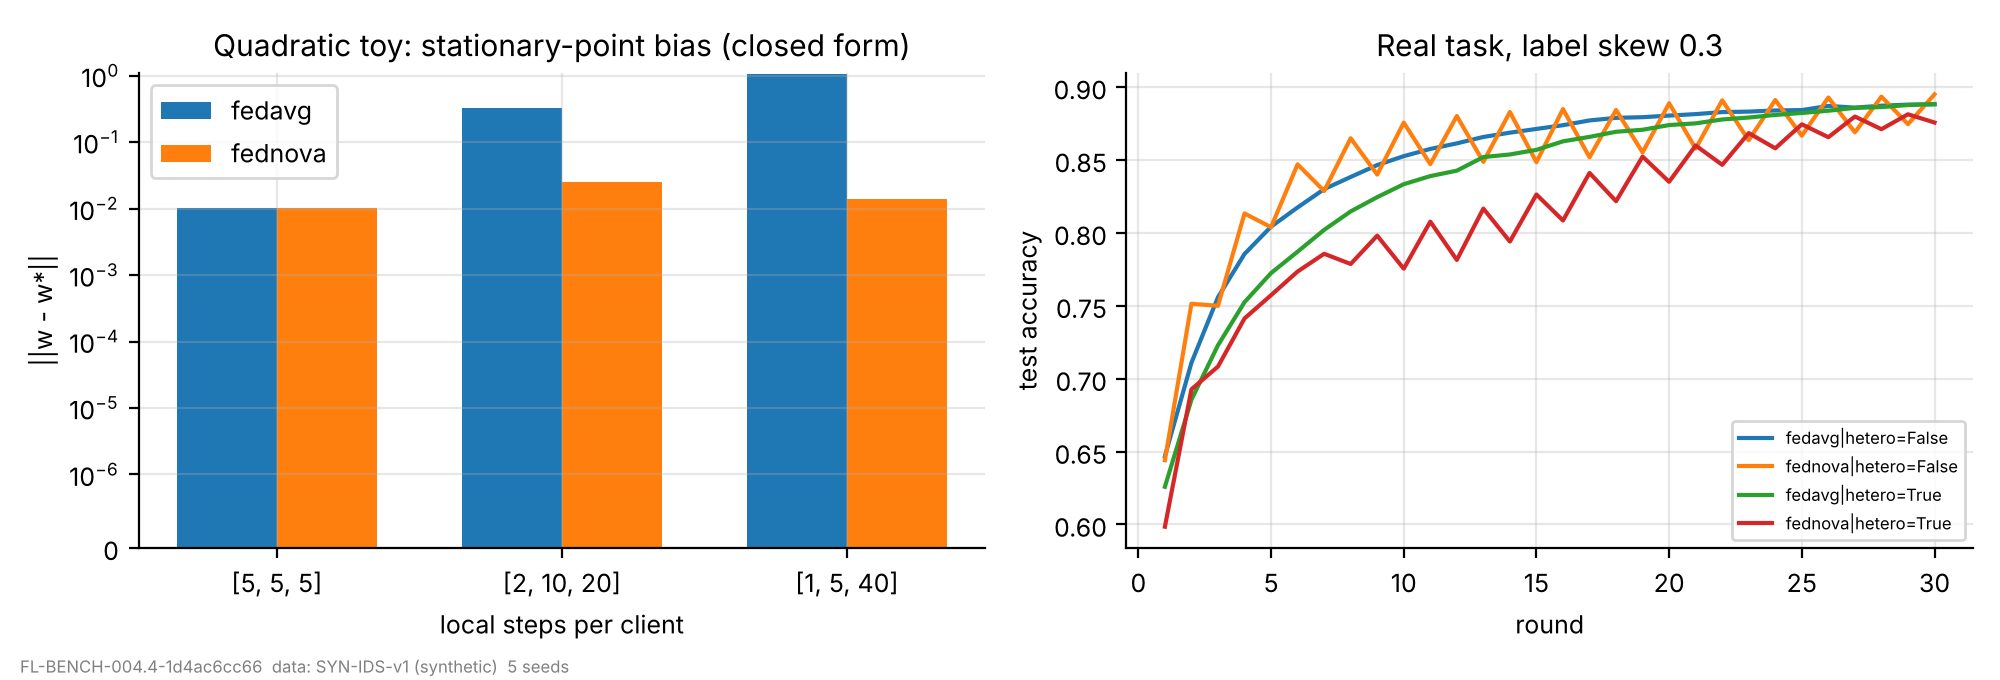

In [10]:
show_fig('task_4_4_fednova.png')

## 15. Interpretation of results
The numbers are computed in the next cell from the stored data; the text interprets only what that cell prints.

Toy problem: FedNova reaches the true weighted optimum; FedAvg is biased.

In [11]:
show_csv('task_4_4_quadratic_toy.csv')

,local_steps,algo,dist_to_global_optimum
0,"[5, 5, 5]",fedavg,0.0104
1,"[5, 5, 5]",fednova,0.0104
2,"[2, 10, 20]",fedavg,0.3231
3,"[2, 10, 20]",fednova,0.0252
4,"[1, 5, 40]",fedavg,1.0532
5,"[1, 5, 40]",fednova,0.0141


## 16. Limitations
- Synthetic tabular data; small MLP.
- Synthetic data, virtual clients on one machine, 2 CPU cores, no GPU; no real network. Comm. bytes are logical payload sizes.
- No regulatory/compliance conclusion can be drawn from this notebook.

## 17. Conclusions
Implementation validated by identity tests (tests/ and task JSON).

**Jira acceptance:** see `docs/fl_bench_004/results_and_discussion.md` for the criterion-by-criterion verdict (MET / PARTIALLY MET / NOT MET).

## 18. References
`mcmahan2017`, `li2020fedprox`, `karimireddy2020`, `wang2020fednova`, `li2021niid` — details in `docs/fl_bench_004/references.md`.